# Zoo Animal Classification Using Apache Spark MLlib

**Course:** INT315 - Cluster Computing

**Project Number:** 24

**Objective:** To classify animals into seven categories using
their physical and behavioural characteristics.

**Algorithms:**
1. Decision Tree Classifier
2. Random Forest Classifier

In [1]:
# Environment check

import sys
import os
import pyspark
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("PYTHON ENVIRONMENT")
print("-------------------------")
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

print("\nLIBRARY VERSIONS")
print("-------------------------")
print("PySpark:", pyspark.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\nSPARK CONFIGURATION")
print("-------------------------")
print("SPARK_HOME:", os.environ.get("SPARK_HOME"))
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

print("\nEnvironment check completed!")

PYTHON ENVIRONMENT
-------------------------
Python Version: 3.12.1 (tags/v3.12.1:2305ca5, Dec  7 2023, 22:03:25) [MSC v.1937 64 bit (AMD64)]
Python Executable: c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Scripts\python.exe

LIBRARY VERSIONS
-------------------------
PySpark: 4.2.0
Pandas: 3.1.1
NumPy: 2.5.4

SPARK CONFIGURATION
-------------------------
SPARK_HOME: C:\spark\spark-4.2.0-bin-hadoop3
JAVA_HOME: C:\Program Files\Eclipse Adoptium\jdk-17.0.20.8-hotspot

Environment check completed!


In [2]:
# Create Spark Session

import os
import sys

# Configure Python for Spark workers
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

# Create Spark Session
spark = SparkSession.builder \
    .appName("Zoo Animal Classification") \
    .master("local[2]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()

print("Spark Session Created Successfully!")
print("Spark Version:", spark.version)
print("Application Name:", spark.sparkContext.appName)

c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark Session Created Successfully!
Spark Version: 4.2.0
Application Name: Zoo Animal Classification


What is a Spark Session?

It is the entry point for working with Spark. We'll use it to load the dataset, process animal characteristics, train MLlib models and make predictions.

In [3]:
# Load Zoo dataset

file_path = "data/zoo.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Zoo Dataset Loaded Successfully!")

Zoo Dataset Loaded Successfully!


- spark.read.csv() reads the CSV file.
- header=True treats the first row as column names.
- inferSchema=True automatically detects data types.

In [4]:
# Display first 10 records
df.show(10)

# Display dataset structure
df.printSchema()

# Check total rows and columns
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

+-----------+----+--------+----+----+--------+-------+--------+-------+--------+--------+--------+----+----+----+--------+-------+----------+
|animal_name|hair|feathers|eggs|milk|airborne|aquatic|predator|toothed|backbone|breathes|venomous|fins|legs|tail|domestic|catsize|class_type|
+-----------+----+--------+----+----+--------+-------+--------+-------+--------+--------+--------+----+----+----+--------+-------+----------+
|   aardvark|   1|       0|   0|   1|       0|      0|       1|      1|       1|       1|       0|   0|   4|   0|       0|      1|         1|
|   antelope|   1|       0|   0|   1|       0|      0|       0|      1|       1|       1|       0|   0|   4|   1|       0|      1|         1|
|       bass|   0|       0|   1|   0|       0|      1|       1|      1|       1|       0|       0|   1|   0|   1|       0|      0|         4|
|       bear|   1|       0|   0|   1|       0|      0|       1|      1|       1|       1|       0|   0|   4|   0|       0|      1|         1|
|     

What are we checking?
- show(10) displays the first 10 animals.
- printSchema() shows column names and data types.
- count() tells us the total number of animal records.

In [5]:
# Statistical summary of the dataset

df.describe().show()

+-------+-----------+-------------------+-------------------+-------------------+------------------+-------------------+-------------------+------------------+-------------------+------------------+------------------+-------------------+-------------------+------------------+-------------------+-------------------+------------------+------------------+
|summary|animal_name|               hair|           feathers|               eggs|              milk|           airborne|            aquatic|          predator|            toothed|          backbone|          breathes|           venomous|               fins|              legs|               tail|           domestic|           catsize|        class_type|
+-------+-----------+-------------------+-------------------+-------------------+------------------+-------------------+-------------------+------------------+-------------------+------------------+------------------+-------------------+-------------------+------------------+--------------

What does describe() calculate?
- Count: Number of records.
- Mean: Average value.
- Standard deviation: How much values vary.
- Minimum: Smallest value.
- Maximum: Largest value.

This helps us understand the distribution of animal characteristics.

In [6]:
# Check missing values

from pyspark.sql import functions as F

missing_values = df.select([
    F.sum(
        F.col(column).isNull().cast("int")
    ).alias(column)
    for column in df.columns
])

missing_values.show()

+-----------+----+--------+----+----+--------+-------+--------+-------+--------+--------+--------+----+----+----+--------+-------+----------+
|animal_name|hair|feathers|eggs|milk|airborne|aquatic|predator|toothed|backbone|breathes|venomous|fins|legs|tail|domestic|catsize|class_type|
+-----------+----+--------+----+----+--------+-------+--------+-------+--------+--------+--------+----+----+----+--------+-------+----------+
|          0|   0|       0|   0|   0|       0|      0|       0|      0|       0|       0|       0|   0|   0|   0|       0|      0|         0|
+-----------+----+--------+----+----+--------+-------+--------+-------+--------+--------+--------+----+----+----+--------+-------+----------+



In [7]:
# Calculate duplicate records

total_records = df.count()
unique_records = df.dropDuplicates().count()

duplicate_records = total_records - unique_records

print("Total Records:", total_records)
print("Unique Records:", unique_records)
print("Duplicate Records:", duplicate_records)

Total Records: 350
Unique Records: 350
Duplicate Records: 0


In [8]:
# Count animals in each category

from pyspark.sql.functions import count

class_distribution = (
    df.groupBy("class_type")
      .agg(count("*").alias("animal_count"))
      .orderBy("class_type")
)

class_distribution.show()

+----------+------------+
|class_type|animal_count|
+----------+------------+
|         1|         100|
|         2|          62|
|         3|          32|
|         4|          51|
|         5|          21|
|         6|          39|
|         7|          45|
+----------+------------+



c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


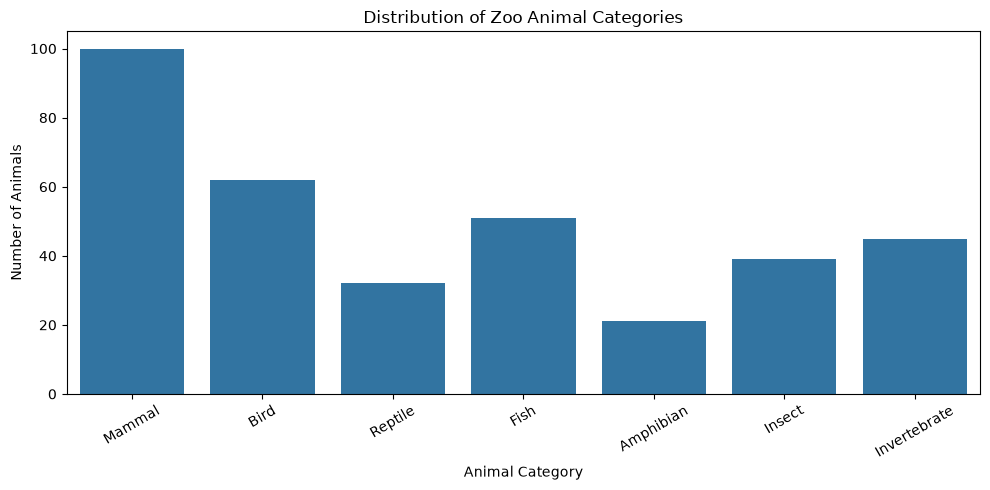

In [9]:
# Visualize animal category distribution

# Convert Spark DataFrame to Pandas
class_pd = class_distribution.toPandas()

# Map class numbers to animal names
class_names = {
    1: "Mammal",
    2: "Bird",
    3: "Reptile",
    4: "Fish",
    5: "Amphibian",
    6: "Insect",
    7: "Invertebrate"
}

class_pd["animal_category"] = class_pd["class_type"].map(class_names)

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_pd,
    x="animal_category",
    y="animal_count"
)

plt.title("Distribution of Zoo Animal Categories")
plt.xlabel("Animal Category")
plt.ylabel("Number of Animals")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# Prepare the dataset for machine learning

# Define input features and target column

feature_columns = [
    column for column in df.columns
    if column not in ["animal_name", "class_type"]
]

target_column = "class_type"

print("Input Features:")
print(feature_columns)

print("\nTotal Input Features:", len(feature_columns))
print("Target Column:", target_column)

Input Features:
['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail', 'domestic', 'catsize']

Total Input Features: 16
Target Column: class_type


Input features (X): 16 animal characteristics.

Target (Y): class_type.

In [11]:
# Create the feature vector using VectorAssembler

from pyspark.ml.feature import VectorAssembler

# Create VectorAssembler
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

# Transform the dataset
data = assembler.transform(df)

# Display the result
data.select("features", "class_type").show(5, truncate=False)

+-----------------------------------------------------------------+----------+
|features                                                         |class_type|
+-----------------------------------------------------------------+----------+
|(16,[0,3,6,7,8,9,12,15],[1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0])       |1         |
|(16,[0,3,7,8,9,12,13,15],[1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0])      |1         |
|(16,[2,5,6,7,8,11,13],[1.0,1.0,1.0,1.0,1.0,1.0,1.0])             |4         |
|(16,[0,3,6,7,8,9,12,15],[1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0])       |1         |
|(16,[0,3,6,7,8,9,12,13,15],[1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0])|1         |
+-----------------------------------------------------------------+----------+
only showing top 5 rows


Spark MLlib requires all input features to be combined into one vector column called features.

VectorAssembler combines 16 separate columns into a single numerical vector. Spark MLlib uses this vector as the model's input.

In [12]:
# Split dataset into training and testing data

train_data, test_data = data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training Records:", train_data.count())
print("Testing Records:", test_data.count())
print("Total Records:", train_data.count() + test_data.count())

Training Records: 296
Testing Records: 54
Total Records: 350


In [13]:
# Train Decision Tree Classifier

from pyspark.ml.classification import DecisionTreeClassifier

# Initialize Decision Tree Classifier
dt = DecisionTreeClassifier(
    labelCol="class_type",
    featuresCol="features",
    seed=42
)

# Train the model
dt_model = dt.fit(train_data)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


A Decision Tree works like a flowchart. It makes decisions based on animal characteristics to predict the animal category.


What does fit() do?

It learns patterns from the 296 training records and builds a decision tree that can classify animals.

In [14]:
# Generate predictions using Decision Tree

dt_predictions = dt_model.transform(test_data)

# Display actual and predicted categories
dt_predictions.select(
    "class_type",
    "prediction",
    "probability"
).show(10, truncate=False)

+----------+----------+----------------------------------------------------------------+
|class_type|prediction|probability                                                     |
+----------+----------+----------------------------------------------------------------+
|1         |1.0       |[0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0]                               |
|1         |1.0       |[0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0]                               |
|4         |4.0       |[0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0]                               |
|1         |1.0       |[0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0]                               |
|4         |4.0       |[0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0]                               |
|6         |6.0       |[0.0,0.0,0.0,0.0,0.0,0.0,0.8095238095238095,0.19047619047619047]|
|3         |3.0       |[0.0,0.0,0.0,0.8064516129032258,0.0,0.1935483870967742,0.0,0.0] |
|3         |3.0       |[0.0,0.0,0.0,0.8064516129032258,0.0,0.1935483870967742,0.0,0.0] |
|1         |1.0      

class_type: Actual animal category.

prediction: Category predicted by the model.

probability: Model's estimated probabilities for each category.

In [15]:
# Evaluate Decision Tree
# Calculate accuracy, precision, recall and F1-score

from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Create accuracy evaluator
evaluator = MulticlassClassificationEvaluator(
    labelCol="class_type",
    predictionCol="prediction",
    metricName="accuracy"
)

# Calculate accuracy
dt_accuracy = evaluator.evaluate(dt_predictions)

# Calculate precision, recall and F1-score
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="class_type",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="class_type",
    predictionCol="prediction",
    metricName="weightedRecall"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="class_type",
    predictionCol="prediction",
    metricName="f1"
)

dt_precision = precision_evaluator.evaluate(dt_predictions)
dt_recall = recall_evaluator.evaluate(dt_predictions)
dt_f1 = f1_evaluator.evaluate(dt_predictions)

# Display results
print("Decision Tree Evaluation Results")
print("--------------------------------")
print("Accuracy:  ", round(dt_accuracy * 100, 2), "%")
print("Precision: ", round(dt_precision * 100, 2), "%")
print("Recall:    ", round(dt_recall * 100, 2), "%")
print("F1-Score:  ", round(dt_f1 * 100, 2), "%")

Decision Tree Evaluation Results
--------------------------------
Accuracy:   90.74 %
Precision:  94.26 %
Recall:     90.74 %
F1-Score:   90.32 %


Accuracy: Percentage of correct predictions.

Precision: How often the model's predicted categories are correct.

Recall: How well the model identifies animals belonging to each actual category.

F1-score: Balance between precision and recall.

c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


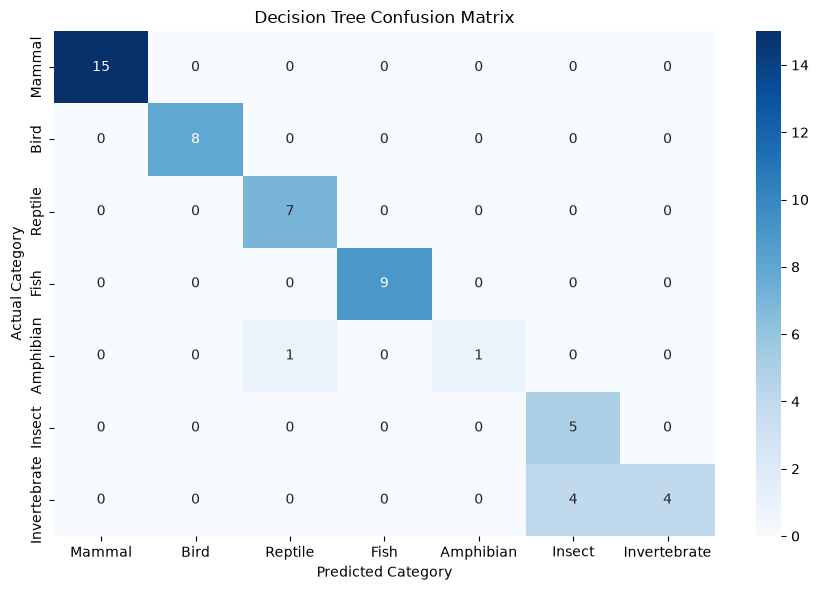

In [16]:
# Generate Decision Tree confusion matrix

from sklearn.metrics import confusion_matrix

# Convert Decision Tree predictions to Pandas
dt_results = dt_predictions.select(
    "class_type",
    "prediction"
).toPandas()

# Generate confusion matrix
dt_cm = confusion_matrix(
    dt_results["class_type"],
    dt_results["prediction"],
    labels=[1, 2, 3, 4, 5, 6, 7]
)

# Plot confusion matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Mammal", "Bird", "Reptile", "Fish",
        "Amphibian", "Insect", "Invertebrate"
    ],
    yticklabels=[
        "Mammal", "Bird", "Reptile", "Fish",
        "Amphibian", "Insect", "Invertebrate"
    ]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [17]:
# Train Random Forest Classifier

from pyspark.ml.classification import RandomForestClassifier

# Initialize Random Forest Classifier
rf = RandomForestClassifier(
    labelCol="class_type",
    featuresCol="features",
    numTrees=100,
    seed=42
)

# Train the model
rf_model = rf.fit(train_data)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Random Forest combines multiple Decision Trees and uses their predictions to make a final classification. It often performs better than a single Decision Tree.


What is numTrees=100?

It means the Random Forest will build 100 Decision Trees and combine their predictions.

In [18]:
# Generate Random Forest predictions

rf_predictions = rf_model.transform(test_data)

# Display actual and predicted categories
rf_predictions.select(
    "class_type",
    "prediction",
    "probability"
).show(10, truncate=False)

+----------+----------+---------------------------------------------------------------------------------------------------------------------------------------------------+
|class_type|prediction|probability                                                                                                                                        |
+----------+----------+---------------------------------------------------------------------------------------------------------------------------------------------------+
|1         |1.0       |[0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0]                                                                                                                  |
|1         |1.0       |[0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0]                                                                                                                  |
|4         |4.0       |[0.0,0.02464552348375877,0.012016129032258065,0.04399891364951114,0.8011726132980654,0.02051338756549439,0.0024489795

In [19]:
# Evaluate Random Forest

# Calculate Random Forest evaluation metrics

rf_accuracy = evaluator.evaluate(rf_predictions)
rf_precision = precision_evaluator.evaluate(rf_predictions)
rf_recall = recall_evaluator.evaluate(rf_predictions)
rf_f1 = f1_evaluator.evaluate(rf_predictions)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("Accuracy:  ", round(rf_accuracy, 4))
print("Precision: ", round(rf_precision, 4))
print("Recall:    ", round(rf_recall, 4))
print("F1-Score:  ", round(rf_f1, 4))

Random Forest Evaluation Results
--------------------------------
Accuracy:   0.9444
Precision:  0.9573
Recall:     0.9444
F1-Score:   0.9424


c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\rahul\MyFiles\College\Sem-7\INT315 - CLUSTER COMPUTING\Project\Zoo Animal Classification\Zoo_Animal_Classification\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


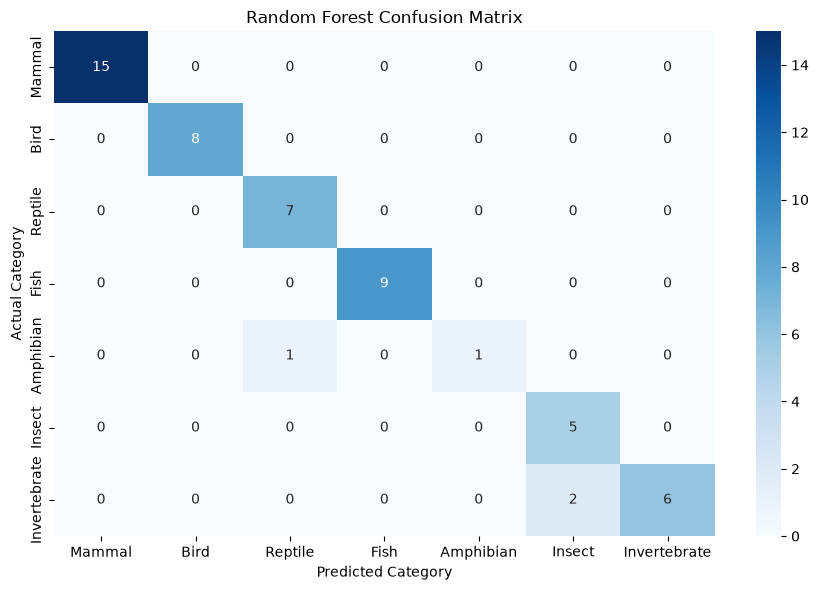

In [20]:
# Generate the confusion matrix

from sklearn.metrics import confusion_matrix

# Convert Spark predictions to Pandas
rf_results = rf_predictions.select(
    "class_type",
    "prediction"
).toPandas()

# Generate confusion matrix
cm = confusion_matrix(
    rf_results["class_type"],
    rf_results["prediction"],
    labels=[1, 2, 3, 4, 5, 6, 7]
)

# Plot confusion matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Mammal", "Bird", "Reptile", "Fish",
        "Amphibian", "Insect", "Invertebrate"
    ],
    yticklabels=[
        "Mammal", "Bird", "Reptile", "Fish",
        "Amphibian", "Insect", "Invertebrate"
    ]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

A confusion matrix shows how many animals were correctly and incorrectly classified in each category.

How to read it:
- Diagonal values = correct predictions.
- Values outside the diagonal = incorrect predictions.
- Rows = actual categories.
- Columns = predicted categories.

Note: We're using scikit-learn only to calculate and visualize the confusion matrix; both ML models remain trained using Spark MLlib.

      Metric  Decision Tree  Random Forest
0   Accuracy       0.907407       0.944444
1  Precision       0.942644       0.957341
2     Recall       0.907407       0.944444
3   F1-Score       0.903175       0.942416


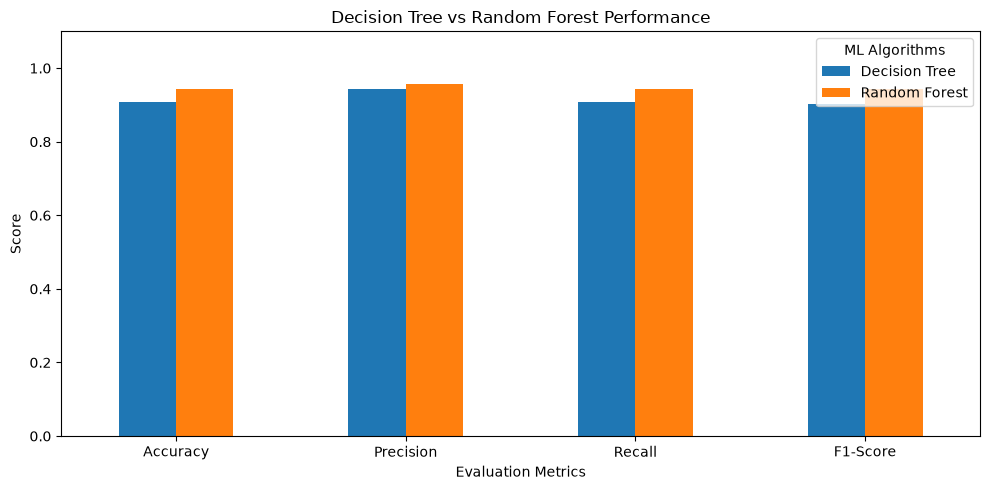

In [21]:
# Comparison of both models
# Create a comparison chart


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare comparison data
comparison_data = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Decision Tree": [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1
    ],
    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print(comparison_data)

# Plot comparison
comparison_data.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Decision Tree vs Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="ML Algorithms")
plt.tight_layout()
plt.show()

In [22]:
# Save both trained models

import os

# Create folder to store trained models
os.makedirs("models", exist_ok=True)

# Save Decision Tree model
dt_model.write().overwrite().save("models/decision_tree_model")

# Save Random Forest model
rf_model.write().overwrite().save("models/random_forest_model")

print("Both models saved successfully!")

Both models saved successfully!


This is important because you shouldn't need to train the models every time you want to use them.

In [23]:
# Load the saved Random Forest model

from pyspark.ml.classification import RandomForestClassificationModel

# Load saved Random Forest model
loaded_rf_model = RandomForestClassificationModel.load(
    "models/random_forest_model"
)

print("Random Forest model loaded successfully!")

Random Forest model loaded successfully!


verify that the saved model can be loaded and used for predictions.

In [24]:
# Generate predictions using loaded model
loaded_predictions = loaded_rf_model.transform(test_data)

loaded_predictions.select(
    "class_type",
    "prediction"
).show(10)

+----------+----------+
|class_type|prediction|
+----------+----------+
|         1|       1.0|
|         1|       1.0|
|         4|       4.0|
|         1|       1.0|
|         4|       4.0|
|         6|       6.0|
|         3|       3.0|
|         3|       3.0|
|         1|       1.0|
|         2|       2.0|
+----------+----------+
only showing top 10 rows


In [25]:
# Predict a new animal
# Predict and display class number + class type

# Create a new animal record

new_animal = [(
    1, 0, 0, 1, 0, 0, 1, 1,
    1, 1, 0, 0, 4, 1, 0, 1
)]

new_animal_df = spark.createDataFrame(
    new_animal,
    feature_columns
)

# Convert input features into a vector
new_animal_vector = assembler.transform(new_animal_df)



new_prediction = loaded_rf_model.transform(new_animal_vector)

class_names = {
    1: "Mammal",
    2: "Bird",
    3: "Reptile",
    4: "Fish",
    5: "Amphibian",
    6: "Insect",
    7: "Invertebrate"
}

prediction_row = new_prediction.select("prediction").first()

predicted_class = int(prediction_row["prediction"])
predicted_type = class_names[predicted_class]

print("ANIMAL CLASSIFICATION RESULT")
print("--------------------------------")
print("Predicted Class Number:", predicted_class)
print("Predicted Animal Type:", predicted_type)

ANIMAL CLASSIFICATION RESULT
--------------------------------
Predicted Class Number: 1
Predicted Animal Type: Mammal


# Conclusion

The project **Zoo Animal Classification Using Apache Spark MLlib** successfully demonstrates the application of machine learning algorithms for classifying animals based on their physical and behavioural characteristics.

The dataset contained 350 animal records, 16 input features and 7 animal categories. Data exploration confirmed that there were no missing values or duplicate records.

Two classification algorithms, Decision Tree and Random Forest, were implemented using Apache Spark MLlib. Both models were trained and evaluated using the same training and testing datasets.

The Decision Tree model achieved an accuracy of 90.74%, while the Random Forest model achieved 94.44% accuracy. Random Forest also performed better across weighted and macro precision, recall and F1-score metrics.

The trained models were saved and successfully loaded again. The saved Random Forest model also demonstrated its ability to predict the category of a new animal record.

Overall, Random Forest was the better-performing algorithm in this experiment. This project demonstrates how Apache Spark MLlib can be used for data processing, machine learning model training, evaluation and prediction.